In [1]:
import pandas as pd

In [2]:
import numpy as np


In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [10]:
df_google = pd.read_csv("google_trend_topic.csv.csv")

In [13]:
df_google.head()

,Time,Black Friday
0,2021-01-01,2
1,2021-02-01,2
2,2021-03-01,1
3,2021-04-01,1
4,2021-05-01,1


In [14]:
df_google.shape

(60, 2)

In [15]:
df_google.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Time          60 non-null     str  
 1   Black Friday  60 non-null     int64
dtypes: int64(1), str(1)
memory usage: 1.7 KB


In [16]:
df_google.isnull().sum()


Time            0
Black Friday    0
dtype: int64

In [17]:
df_google['Time'] = pd.to_datetime(df_google['Time'])

In [18]:
df_google.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Time          60 non-null     datetime64[us]
 1   Black Friday  60 non-null     int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 1.1 KB


In [19]:
df_google['Black Friday'].describe()

count     60.000000
mean       6.166667
std       17.991680
min        0.000000
25%        1.000000
50%        1.000000
75%        2.000000
max      100.000000
Name: Black Friday, dtype: float64

In [20]:
df_google.sort_values(
    by='Black Friday',
    ascending=False
).head(10)

,Time,Black Friday
58,2025-11-01,100
46,2024-11-01,79
34,2023-11-01,65
10,2021-11-01,23
22,2022-11-01,12
59,2025-12-01,7
47,2024-12-01,6
57,2025-10-01,5
33,2023-10-01,4
45,2024-10-01,4


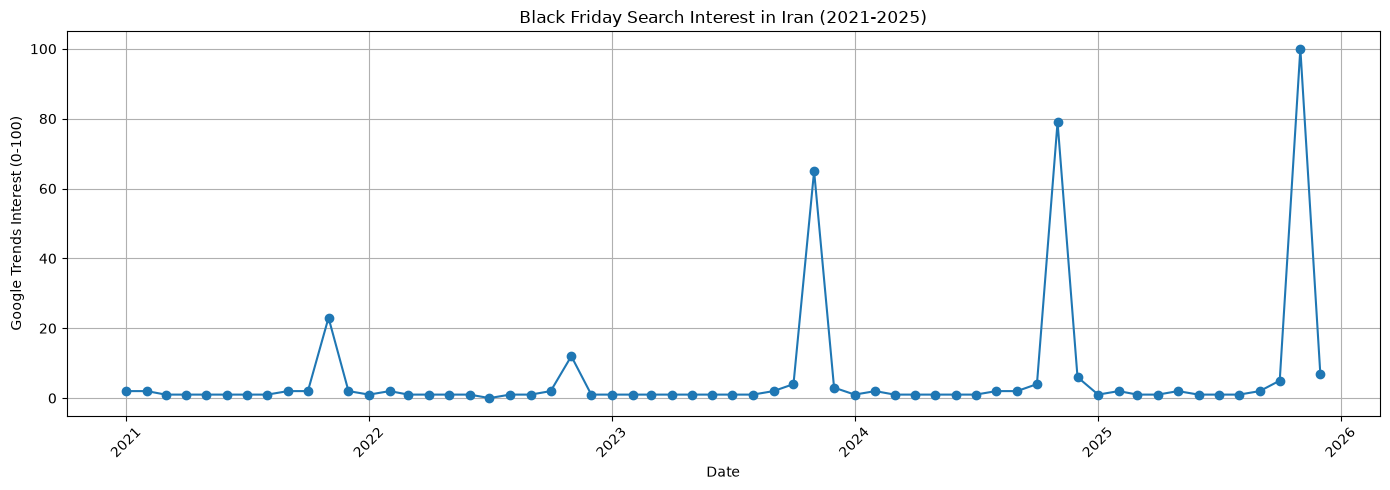

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(
    df_google['Time'],
    df_google['Black Friday'],
    marker='o'
)

plt.title('Black Friday Search Interest in Iran (2021-2025)')
plt.xlabel('Date')
plt.ylabel('Google Trends Interest (0-100)')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [24]:
df_google['Month'] = df_google['Time'].dt.month

monthly_avg = df_google.groupby('Month')['Black Friday'].mean()

monthly_avg

Month
1      1.2
2      1.8
3      1.0
4      1.0
5      1.2
6      1.0
7      0.8
8      1.2
9      1.8
10     3.4
11    55.8
12     3.8
Name: Black Friday, dtype: float64

In [25]:
monthly_avg.sort_values(ascending=False)

Month
11    55.8
12     3.8
10     3.4
2      1.8
9      1.8
8      1.2
1      1.2
5      1.2
4      1.0
3      1.0
6      1.0
7      0.8
Name: Black Friday, dtype: float64

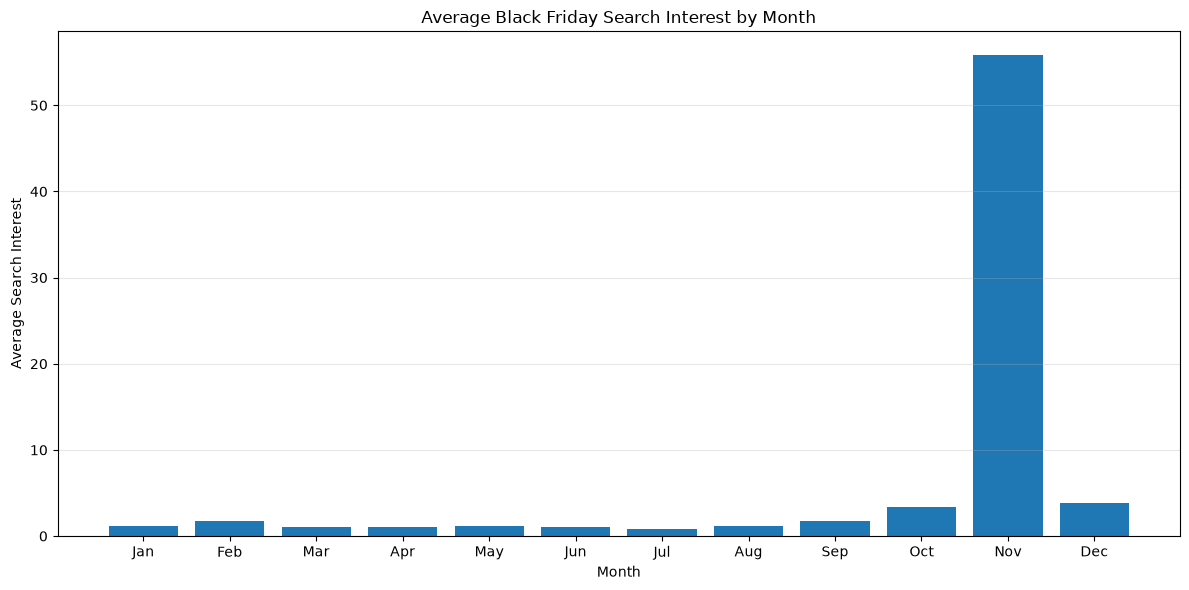

In [26]:
plt.figure(figsize=(12, 6))

plt.bar(monthly_avg.index, monthly_avg.values)

plt.title('Average Black Friday Search Interest by Month')
plt.xlabel('Month')
plt.ylabel('Average Search Interest')

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
df_google['Year'] = df_google['Time'].dt.year

seasonal_trend = df_google[
    df_google['Month'].isin([10, 11, 12])
].pivot(
    index='Year',
    columns='Month',
    values='Black Friday'
)

seasonal_trend

Month,10,11,12
Year,,,
2021,2,23,2
2022,2,12,1
2023,4,65,3
2024,4,79,6
2025,5,100,7


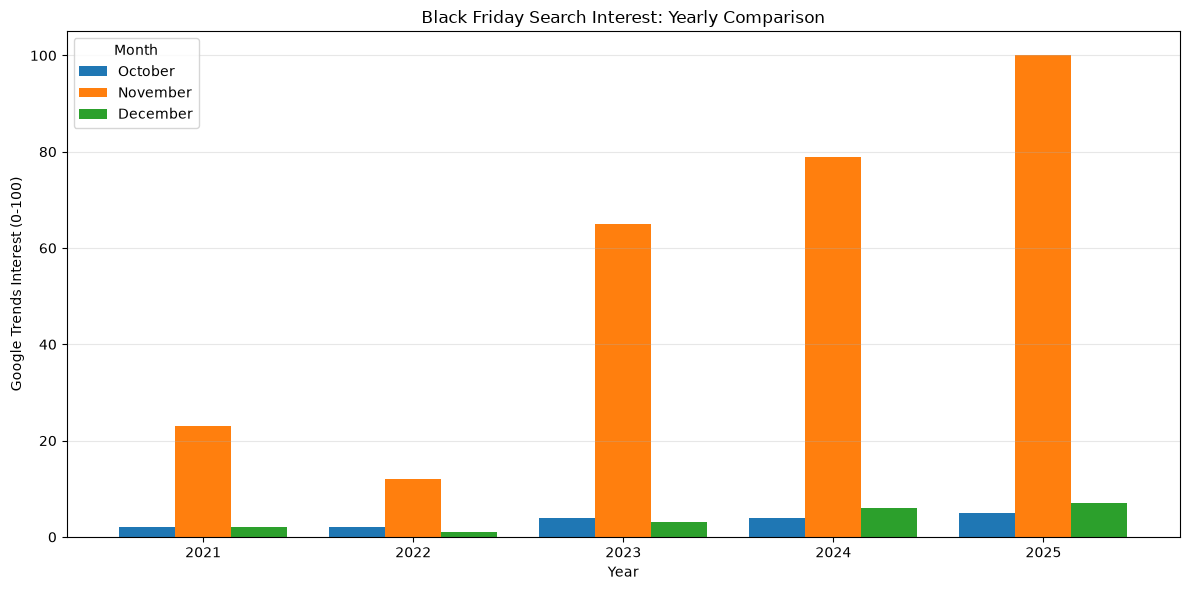

In [28]:
seasonal_trend.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Black Friday Search Interest: Yearly Comparison')
plt.xlabel('Year')
plt.ylabel('Google Trends Interest (0-100)')

plt.xticks(rotation=0)
plt.legend(
    ['October', 'November', 'December'],
    title='Month'
)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
november_data = seasonal_trend[11]

november_growth = november_data.pct_change() * 100

november_growth

Year
2021           NaN
2022    -47.826087
2023    441.666667
2024     21.538462
2025     26.582278
Name: 11, dtype: float64

In [31]:
yearly_avg = df_google.groupby('Year')['Black Friday'].mean()

In [33]:
yearly_avg_table = yearly_avg.reset_index()

yearly_avg_table.columns = ['Year', 'Average Search Interest']

yearly_avg_table.round(2)

,Year,Average Search Interest
0,2021,3.25
1,2022,2.00
2,2023,6.83
3,2024,8.42
4,2025,10.33


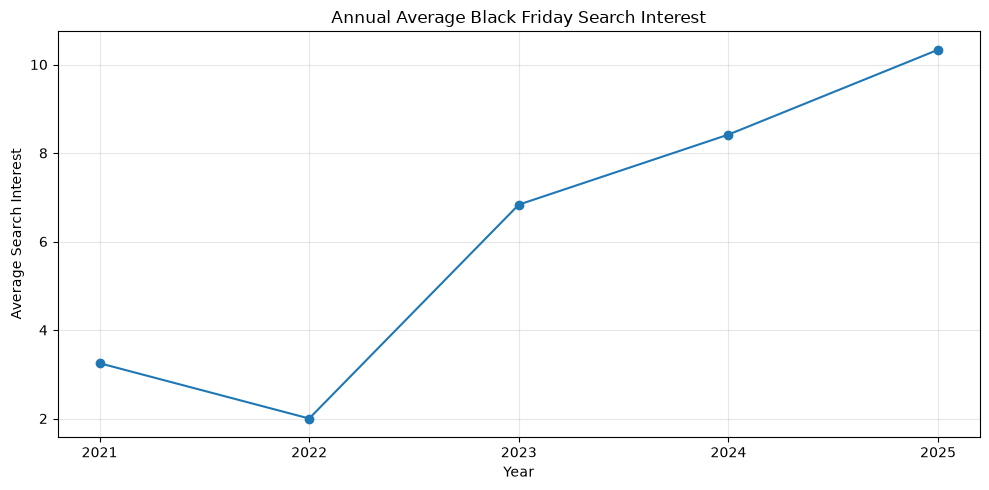

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_avg.index,
    yearly_avg.values,
    marker='o'
)

plt.title('Annual Average Black Friday Search Interest')
plt.xlabel('Year')
plt.ylabel('Average Search Interest')

plt.grid(alpha=0.3)
plt.xticks(yearly_avg.index)
plt.tight_layout()
plt.show()

In [36]:
yearly_total = df_google.groupby('Year')['Black Friday'].sum()

november_share = (
    seasonal_trend[11] / yearly_total
) * 100

november_share

Year
2021    58.974359
2022    50.000000
2023    79.268293
2024    78.217822
2025    80.645161
dtype: float64

In [37]:
november_share_table = november_share.reset_index()

november_share_table.columns = [
    'Year',
    'November Share (%)'
]

november_share_table.round(2)

,Year,November Share (%)
0,2021,58.97
1,2022,50.00
2,2023,79.27
3,2024,78.22
4,2025,80.65


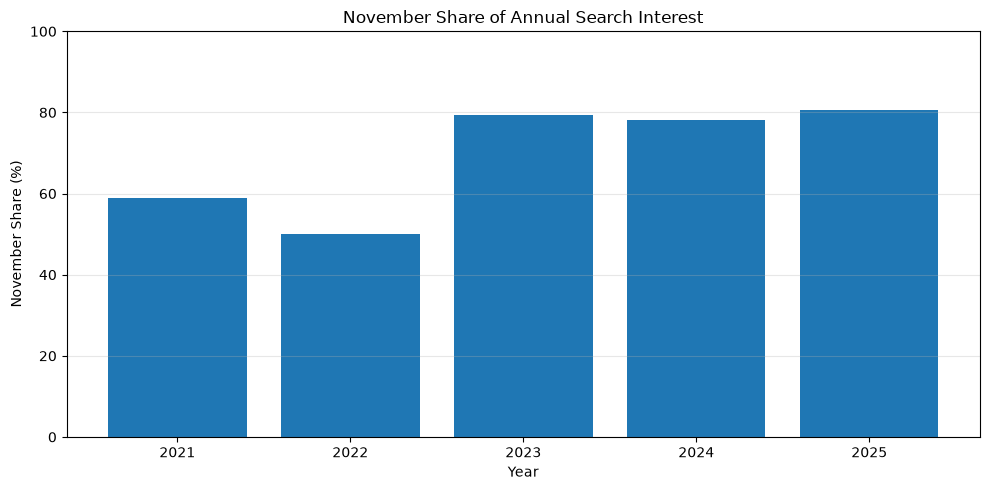

In [38]:
plt.figure(figsize=(10, 5))

plt.bar(
    november_share.index,
    november_share.values
)

plt.title('November Share of Annual Search Interest')
plt.xlabel('Year')
plt.ylabel('November Share (%)')

plt.xticks(november_share.index)
plt.ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()